# Phase 6.3 — Fraud Detection Feature Engineering

## Banking Risk Intelligence Platform

### 1. Executive Summary and Architectural Objective
Following the exploratory findings in **Phase 6.2 (EDA)**, Phase 6.3 establishes a production-grade, leakage-safe **Feature Engineering and Dataset Splitting Pipeline** for transaction fraud detection.

#### Engineering Focus Areas
1. **Transaction Amount Transformations**:
   - `Amount_log = np.log1p(Amount)`: Compresses extreme monetary right-skew without distorting zero amounts.
   - `is_zero_amount = (Amount == 0).astype(int)`: Binary indicator capturing micro-authorization and card-testing pings (found to be 8.4× more prevalent in fraud during Phase 6.2).
2. **Transaction Elapsed Time Scaling**:
   - Continuous elapsed seconds feature `Time` is transformed via a **leakage-safe learned scaler** (e.g., `RobustScaler`), fitted strictly on the training partition.
   - *Methodological note*: We deliberately **do not derive hour-of-day or assume calendar diurnal patterns** because `Time` records elapsed seconds across a 48-hour sample without a verified wall-clock or timezone anchor.
3. **PCA Interaction Terms**:
   - `V14_V4_interaction = V14 * V4`: Interaction between the two highest-divergence features identified via Mann–Whitney U testing ($p < 10^{-235}$).
   - `V12_V11_interaction = V12 * V11`: Interaction between complementary negative and positive separating components.
4. **Leakage-Safe Partitioning Strategy**:
   - Rigorous investigation and quantitative benchmarking of two data splitting paradigms:
     - **Strategy A: Stratified Random Split** (64% Train / 16% Val / 20% Test)
     - **Strategy B: Chronological Sequential Split** based on elapsed `Time`
   - Evaluation of class balance stability, non-stationarity risks, and business applicability.
5. **Quality Verification & Modular Pipeline**:
   - Code packaged into reusable module `src/fraud_feature_engineering.py`.
   - Comprehensive validation against data leakage, nulls, inf values, and index contamination.

### 2. Environment Setup and Library Imports
We configure the runtime environment and import analysis tools, scikit-learn preprocessing utilities, and our custom feature engineering module.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add src to path for modular imports
sys.path.append(str(Path('../src').resolve()))
if 'src' not in sys.path:
    sys.path.append('src')

from fraud_feature_engineering import (
    FraudFeatureEngineer,
    clean_raw_fraud_data,
    split_fraud_data_stratified,
    split_fraud_data_chronological
)

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment configured. Dependencies and custom module loaded successfully.")

Environment configured. Dependencies and custom module loaded successfully.


### 3. Dataset Loading and Deduplication
We ingest `data/raw/creditcard.csv` and apply reproducible deduplication using `clean_raw_fraud_data()`.
The raw dataset remains strictly read-only.

In [2]:
data_path = Path('../data/raw/creditcard.csv')
if not data_path.exists():
    data_path = Path('data/raw/creditcard.csv')

df_raw = pd.read_csv(data_path)
print(f"Raw dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

# Apply cleaning
df = clean_raw_fraud_data(df_raw)
print(f"Cleaned dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

n_dups = len(df_raw) - len(df)
n_legit_clean = (df['Class'] == 0).sum()
n_fraud_clean = (df['Class'] == 1).sum()
fraud_rate = (n_fraud_clean / len(df)) * 100

print(f"Duplicates removed: {n_dups:,}")
print(f"Legitimate records: {n_legit_clean:,} ({100 - fraud_rate:.4f}%)")
print(f"Fraudulent records: {n_fraud_clean:,} ({fraud_rate:.4f}%)")

Raw dataset shape: 284,807 rows x 31 columns


Cleaned dataset shape: 283,726 rows x 31 columns
Duplicates removed: 1,081
Legitimate records: 283,253 (99.8333%)
Fraudulent records: 473 (0.1667%)


### 4. Feature Engineering Architecture & Domain Rationale

We engineer 5 targeted features designed to capture specific fraud mechanics while avoiding feature bloat and collinearity:

| Engineered Feature | Formulation | Domain & Methodological Rationale |
|---|---|---|
| `Amount_log` | $\ln(1 + \text{Amount})$ | Compresses heavy monetary right-skew (max €2,125.87 in fraud, €25,691.16 in legit) to stabilize variance and gradient steps without distorting zero amounts. |
| `is_zero_amount` | $\mathbb{I}(\text{Amount} = 0)$ | Exploits account verification ping behavior (zero-amount pings occur in 5.29% of fraud vs 0.63% of legit transactions; an 8.4× relative risk ratio). |
| `Time_scaled` | $\frac{\text{Time} - \text{median}(\text{Time}_{\text{train}})}{\text{IQR}(\text{Time}_{\text{train}})}$ | Robust scaling of continuous elapsed seconds. Eliminates magnitude bias without leaking validation/test time horizons. |
| `V14_V4_interaction` | $V_{14} \times V_4$ | Combines the top negative separating component ($V_{14}$, fraud median $-6.59$) with the top positive separating component ($V_4$, fraud median $+4.10$). Their product strongly polarizes fraud cases. |
| `V12_V11_interaction` | $V_{12} \times V_{11}$ | Cross-feature non-linear interaction between $V_{12}$ (fraud median $-5.44$) and $V_{11}$ (fraud median $+3.53$). |

### 5. Applying the Feature Engineering Transformer
We fit `FraudFeatureEngineer` on the feature matrix $X$ (excluding target `Class`) to verify transformation mechanics and inspect distributions.

In [3]:
X_all = df.drop(columns=['Class'])
y_all = df['Class']

fe_demo = FraudFeatureEngineer(time_scaler='robust', preserve_original=True)
fe_demo.fit(X_all)
X_engineered = fe_demo.transform(X_all)

print(f"Original feature count:   {X_all.shape[1]}")
print(f"Engineered feature count: {X_engineered.shape[1]}")
print(f"\nNew features added: {[c for c in X_engineered.columns if c not in X_all.columns]}")
display(X_engineered[['Amount', 'Amount_log', 'is_zero_amount', 'Time', 'Time_scaled', 'V14_V4_interaction', 'V12_V11_interaction']].head())

Original feature count:   30
Engineered feature count: 35

New features added: ['Amount_log', 'is_zero_amount', 'Time_scaled', 'V14_V4_interaction', 'V12_V11_interaction']


,Amount,Amount_log,is_zero_amount,Time,Time_scaled,V14_V4_interaction,V12_V11_interaction
0,149.62,5.014760,0,0.0,-0.995290,-0.428840,0.340779
1,2.69,1.305626,0,0.0,-0.995290,-0.064432,1.717933
2,378.66,5.939276,0,1.0,-0.995279,-0.063023,0.041269
3,123.50,4.824306,0,1.0,-0.995279,0.248562,-0.040366
4,69.99,4.262539,0,2.0,-0.995267,-0.451265,-0.442850


### 6. Descriptive Statistics: Original vs. Engineered Features
We evaluate the statistical distribution of the newly engineered features partitioned by transaction legitimacy (`Class`).

In [4]:
eval_df = X_engineered.copy()
eval_df['Class'] = y_all.values

eng_cols = ['Amount_log', 'is_zero_amount', 'Time_scaled', 'V14_V4_interaction', 'V12_V11_interaction']

stats_records = []
for col in eng_cols:
    legit_s = eval_df[eval_df['Class'] == 0][col]
    fraud_s = eval_df[eval_df['Class'] == 1][col]
    stats_records.append({
        'Feature': col,
        'Legit_Mean': legit_s.mean(),
        'Legit_Median': legit_s.median(),
        'Legit_Std': legit_s.std(),
        'Fraud_Mean': fraud_s.mean(),
        'Fraud_Median': fraud_s.median(),
        'Fraud_Std': fraud_s.std(),
    })

stats_comp = pd.DataFrame(stats_records)
print("--- Engineered Feature Distributions by Class ---")
display(stats_comp.style.format('{:.4f}', subset=['Legit_Mean', 'Legit_Median', 'Legit_Std', 'Fraud_Mean', 'Fraud_Median', 'Fraud_Std']))

--- Engineered Feature Distributions by Class ---


,Feature,Legit_Mean,Legit_Median,Legit_Std,Fraud_Mean,Fraud_Median,Fraud_Std
0,Amount_log,3.1543,3.1355,1.6560,2.8375,2.3814,2.2127
1,is_zero_amount,0.0063,0.0000,0.0791,0.0529,0.0000,0.2240
2,Time_scaled,0.1192,0.0002,0.5579,-0.0499,-0.1326,0.5716
3,V14_V4_interaction,0.0681,0.0283,1.6096,-38.5468,-26.2780,40.8351
4,V12_V11_interaction,0.0617,0.0523,1.5061,-33.5667,-19.3275,42.2267


### 7. Visualizing Distributional Separation of Engineered Features
We visualize the density and separation of the newly created features across classes.

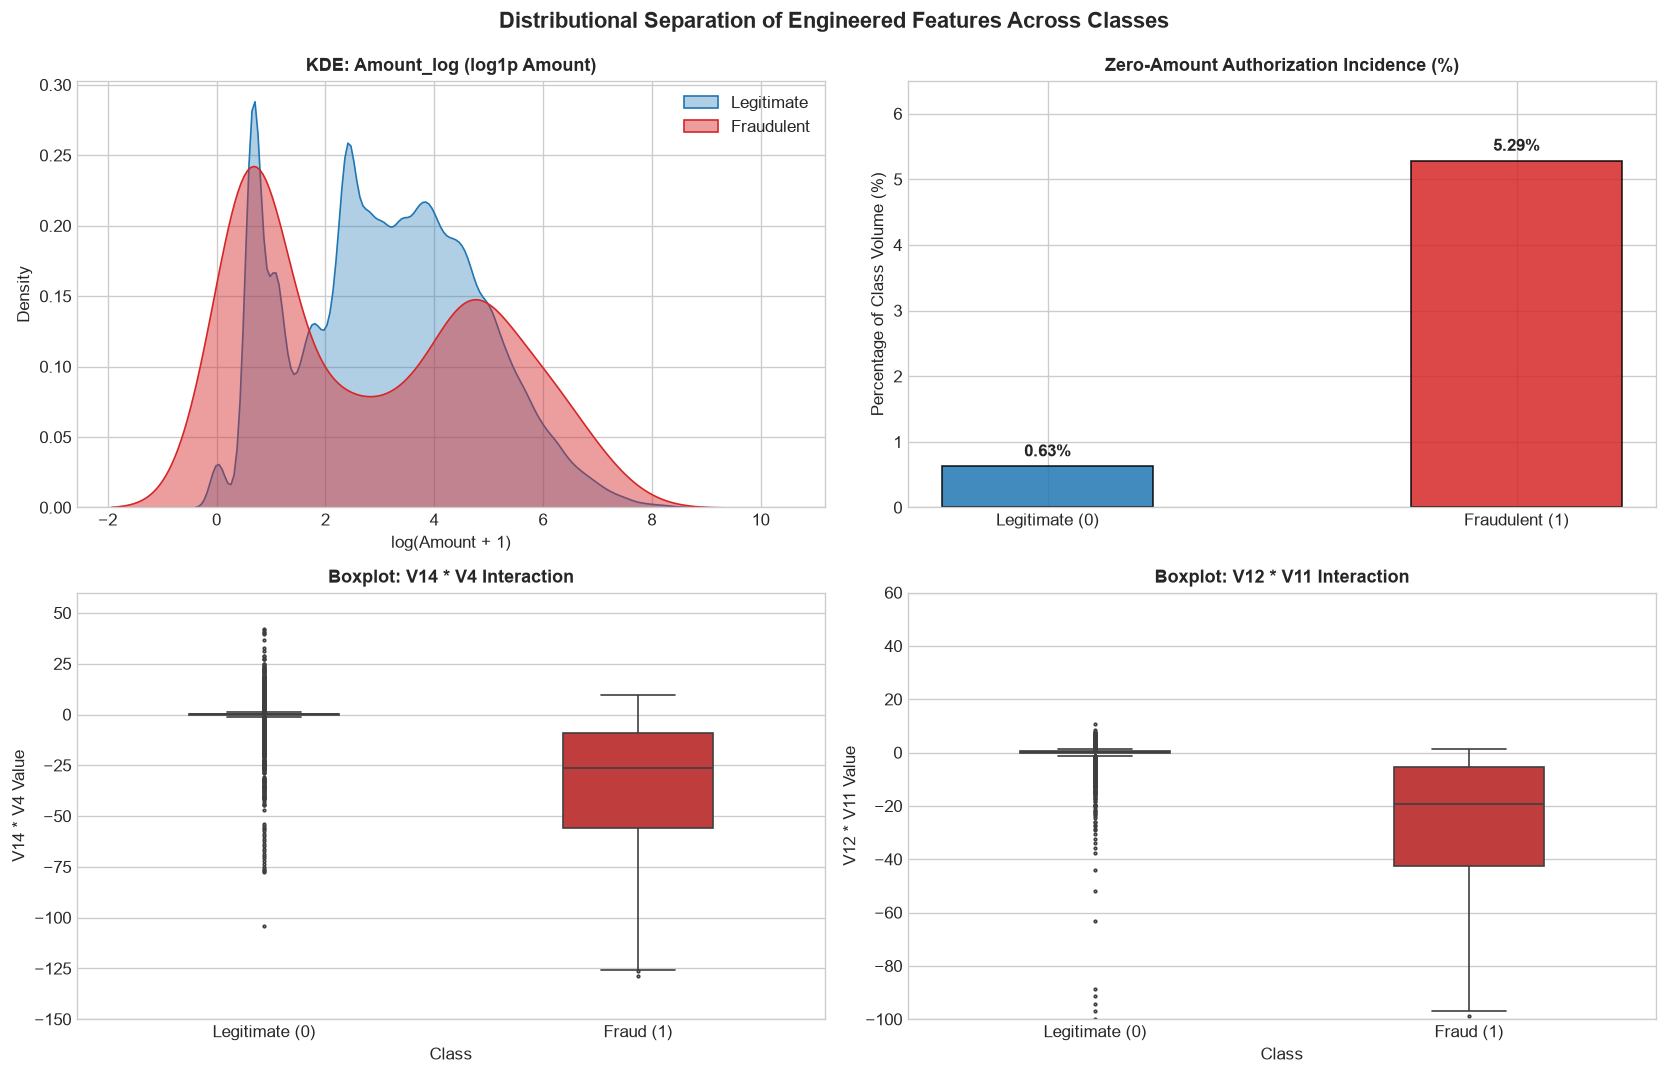

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Plot 1: Amount_log KDE
sns.kdeplot(eval_df[eval_df['Class'] == 0]['Amount_log'], ax=axes[0, 0], color='#1f77b4', label='Legitimate', shade=True, alpha=0.35)
sns.kdeplot(eval_df[eval_df['Class'] == 1]['Amount_log'], ax=axes[0, 0], color='#d62728', label='Fraudulent', shade=True, alpha=0.45)
axes[0, 0].set_title('KDE: Amount_log (log1p Amount)', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('log(Amount + 1)')
axes[0, 0].legend()

# Plot 2: is_zero_amount bar comparison
zero_rates = [
    eval_df[eval_df['Class'] == 0]['is_zero_amount'].mean() * 100,
    eval_df[eval_df['Class'] == 1]['is_zero_amount'].mean() * 100
]
axes[0, 1].bar(['Legitimate (0)', 'Fraudulent (1)'], zero_rates, color=['#1f77b4', '#d62728'], width=0.45, edgecolor='black', alpha=0.85)
axes[0, 1].set_title('Zero-Amount Authorization Incidence (%)', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Percentage of Class Volume (%)')
for i, v in enumerate(zero_rates):
    axes[0, 1].text(i, v + 0.15, f"{v:.2f}%", ha='center', fontweight='bold')
axes[0, 1].set_ylim(0, 6.5)

# Plot 3: V14_V4_interaction Boxplot
sns.boxplot(x='Class', y='V14_V4_interaction', data=eval_df, ax=axes[1, 0], palette=['#1f77b4', '#d62728'], width=0.4, fliersize=1.5)
axes[1, 0].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
axes[1, 0].set_title('Boxplot: V14 * V4 Interaction', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('V14 * V4 Value')
axes[1, 0].set_ylim(-150, 60)

# Plot 4: V12_V11_interaction Boxplot
sns.boxplot(x='Class', y='V12_V11_interaction', data=eval_df, ax=axes[1, 1], palette=['#1f77b4', '#d62728'], width=0.4, fliersize=1.5)
axes[1, 1].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
axes[1, 1].set_title('Boxplot: V12 * V11 Interaction', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('V12 * V11 Value')
axes[1, 1].set_ylim(-100, 60)

plt.suptitle('Distributional Separation of Engineered Features Across Classes', fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

### 8. Correlation and Redundancy Analysis
We evaluate feature correlation with target `Class` and inspect whether the engineered features introduce excessive multicollinearity with their parent components.

--- Correlation of Engineered Features with Target (Class) ---
  V14_V4_interaction    : r = -0.5625
  V12_V11_interaction   : r = -0.5144
  Time_scaled           : r = -0.0124
  Amount_log            : r = -0.0078
  is_zero_amount        : r = +0.0239


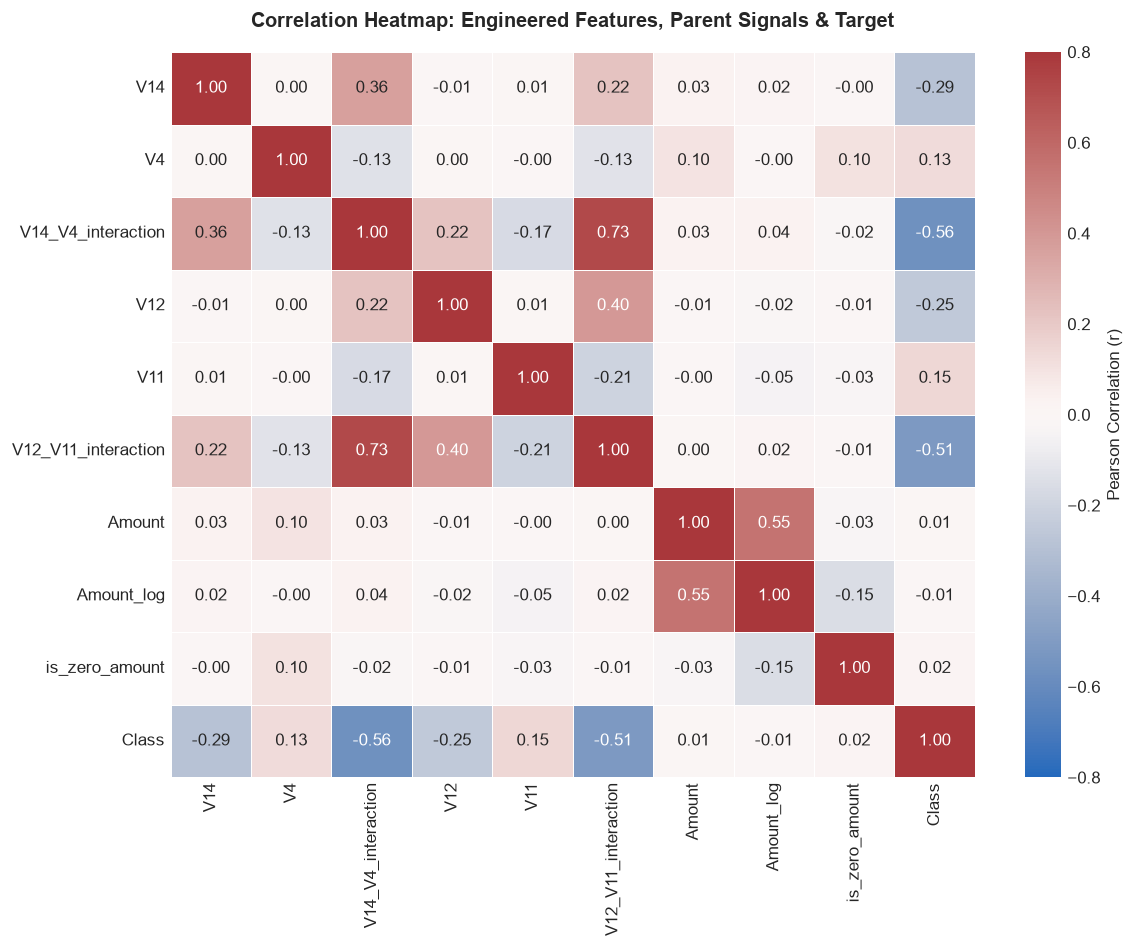

In [6]:
# Target correlation comparison
all_corr = eval_df.corr()['Class'].drop('Class')
eng_corr = all_corr[eng_cols].sort_values()

print("--- Correlation of Engineered Features with Target (Class) ---")
for feat, corr_val in eng_corr.items():
    print(f"  {feat:<22s}: r = {corr_val:+.4f}")

# Pairwise correlation between parent and interaction features
interaction_matrix = eval_df[['V14', 'V4', 'V14_V4_interaction', 'V12', 'V11', 'V12_V11_interaction', 'Amount', 'Amount_log', 'is_zero_amount', 'Class']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(interaction_matrix, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-0.8, vmax=0.8, linewidths=0.5, cbar_kws={'label': 'Pearson Correlation (r)'})
plt.title('Correlation Heatmap: Engineered Features, Parent Signals & Target', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 9. Leakage-Safe Data Splitting Strategies

In credit card fraud modeling, data partition selection is critical:
- **Strategy A: Stratified Random Train / Validation / Test Split** (64% / 16% / 20%)
  - Preserves the exact 0.1667% minority class incidence across all three partitions.
  - Mitigates sampling variance in validation and test partitions (ensuring stable metric estimation).
- **Strategy B: Chronological Train / Validation / Test Split**
  - Respects the temporal arrow of time ($[t_0, t_1] \to (t_1, t_2] \to (t_2, t_{\text{end}}]$).
  - Reflects true out-of-time deployment conditions.

We implement and benchmark both strategies across the cleaned dataset.

In [7]:
# Execute Strategy A: Stratified Split (64 / 16 / 20)
X_tr_strat, X_val_strat, X_te_strat, y_tr_strat, y_val_strat, y_te_strat = split_fraud_data_stratified(
    df, target_col='Class', train_ratio=0.64, val_ratio=0.16, test_ratio=0.20, random_state=RANDOM_STATE
)

# Execute Strategy B: Chronological Split (64 / 16 / 20)
X_tr_chr, X_val_chr, X_te_chr, y_tr_chr, y_val_chr, y_te_chr = split_fraud_data_chronological(
    df, time_col='Time', target_col='Class', train_ratio=0.64, val_ratio=0.16, test_ratio=0.20
)

# Compile comparison table
split_comparison = pd.DataFrame({
    'Stratified_Total': [len(X_tr_strat), len(X_val_strat), len(X_te_strat)],
    'Stratified_Fraud': [y_tr_strat.sum(), y_val_strat.sum(), y_te_strat.sum()],
    'Stratified_Fraud_Pct': [y_tr_strat.mean()*100, y_val_strat.mean()*100, y_te_strat.mean()*100],
    'Chrono_Total': [len(X_tr_chr), len(X_val_chr), len(X_te_chr)],
    'Chrono_Fraud': [y_tr_chr.sum(), y_val_chr.sum(), y_te_chr.sum()],
    'Chrono_Fraud_Pct': [y_tr_chr.mean()*100, y_val_chr.mean()*100, y_te_chr.mean()*100],
    'Chrono_Time_Min': [X_tr_chr['Time'].min(), X_val_chr['Time'].min(), X_te_chr['Time'].min()],
    'Chrono_Time_Max': [X_tr_chr['Time'].max(), X_val_chr['Time'].max(), X_te_chr['Time'].max()]
}, index=['Train (64%)', 'Validation (16%)', 'Test (20%)'])

print("--- Data Splitting Strategy Comparison ---")
display(split_comparison.style.format({
    'Stratified_Total': '{:,}',
    'Stratified_Fraud': '{:,}',
    'Stratified_Fraud_Pct': '{:.4f}%',
    'Chrono_Total': '{:,}',
    'Chrono_Fraud': '{:,}',
    'Chrono_Fraud_Pct': '{:.4f}%',
    'Chrono_Time_Min': '{:,.0f}s',
    'Chrono_Time_Max': '{:,.0f}s'
}))

--- Data Splitting Strategy Comparison ---


,Stratified_Total,Stratified_Fraud,Stratified_Fraud_Pct,Chrono_Total,Chrono_Fraud,Chrono_Fraud_Pct,Chrono_Time_Min,Chrono_Time_Max
Train (64%),"181,584",302,0.1663%,"181,584",347,0.1911%,0s,"125,321s"
Validation (16%),"45,396",76,0.1674%,"45,396",52,0.1145%,"125,322s","145,233s"
Test (20%),"56,746",95,0.1674%,"56,746",74,0.1304%,"145,234s","172,792s"


### 10. Visualizing Partitioning Characteristics and Fraud Distribution
We contrast the temporal coverage and fraud volume consistency of both splitting strategies.

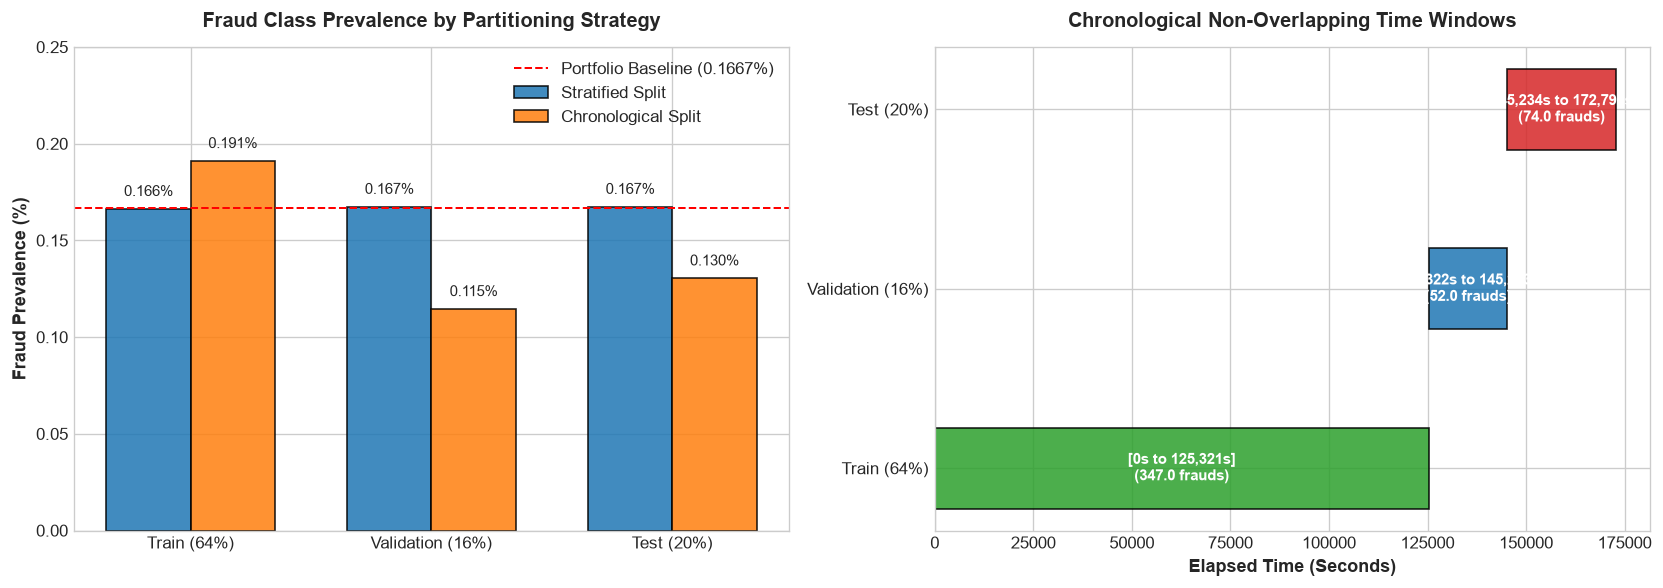

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Fraud Rate Comparison across partitions
partitions = ['Train (64%)', 'Validation (16%)', 'Test (20%)']
x_pos = np.arange(len(partitions))
width = 0.35

rects1 = axes[0].bar(x_pos - width/2, split_comparison['Stratified_Fraud_Pct'], width, label='Stratified Split', color='#1f77b4', edgecolor='black', alpha=0.85)
rects2 = axes[0].bar(x_pos + width/2, split_comparison['Chrono_Fraud_Pct'], width, label='Chronological Split', color='#ff7f0e', edgecolor='black', alpha=0.85)

axes[0].set_ylabel('Fraud Prevalence (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Fraud Class Prevalence by Partitioning Strategy', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(partitions, fontsize=10)
axes[0].axhline(0.1667, color='red', linestyle='--', linewidth=1.2, label='Portfolio Baseline (0.1667%)')
axes[0].legend()

for rect in rects1:
    axes[0].text(rect.get_x() + rect.get_width()/2.0, rect.get_height() + 0.005, f"{rect.get_height():.3f}%", ha='center', va='bottom', fontsize=9)
for rect in rects2:
    axes[0].text(rect.get_x() + rect.get_width()/2.0, rect.get_height() + 0.005, f"{rect.get_height():.3f}%", ha='center', va='bottom', fontsize=9)
axes[0].set_ylim(0, 0.25)

# Plot 2: Chronological Timeline Segments
y_ticks = [0, 1, 2]
t_ranges = [
    (split_comparison.loc['Train (64%)', 'Chrono_Time_Min'], split_comparison.loc['Train (64%)', 'Chrono_Time_Max']),
    (split_comparison.loc['Validation (16%)', 'Chrono_Time_Min'], split_comparison.loc['Validation (16%)', 'Chrono_Time_Max']),
    (split_comparison.loc['Test (20%)', 'Chrono_Time_Min'], split_comparison.loc['Test (20%)', 'Chrono_Time_Max'])
]
colors = ['#2ca02c', '#1f77b4', '#d62728']

for i, (t_start, t_end) in enumerate(t_ranges):
    axes[1].barh(i, t_end - t_start, left=t_start, height=0.45, color=colors[i], edgecolor='black', alpha=0.85)
    axes[1].text((t_start + t_end)/2, i, f"[{int(t_start):,}s to {int(t_end):,}s]\n({split_comparison.iloc[i]['Chrono_Fraud']} frauds)", ha='center', va='center', color='white', fontweight='bold', fontsize=9)

axes[1].set_yticks(y_ticks)
axes[1].set_yticklabels(partitions, fontsize=10)
axes[1].set_xlabel('Elapsed Time (Seconds)', fontsize=11, fontweight='bold')
axes[1].set_title('Chronological Non-Overlapping Time Windows', fontsize=12, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

### 11. Leakage-Safe Pipeline Fitting and Verification
We demonstrate the complete, leak-free pipeline:
1. Split data **before** applying any feature engineering or scaling.
2. Fit `FraudFeatureEngineer` **strictly** on the training partition (`X_tr_strat`).
3. Transform `X_val_strat` and `X_te_strat` using the training-learned parameters.
4. Verify complete absence of NaNs, Infs, index contamination, and target leakage.

In [9]:
# 1. Instantiate transformer
fe_pipeline = FraudFeatureEngineer(time_scaler='robust', preserve_original=True)

# 2. Fit ONLY on train partition
fe_pipeline.fit(X_tr_strat)

# 3. Transform train, validation, and test partitions
X_tr_proc = fe_pipeline.transform(X_tr_strat)
X_val_proc = fe_pipeline.transform(X_val_strat)
X_te_proc = fe_pipeline.transform(X_te_strat)

# 4. Strict Leakage and Integrity Assertions
print("--- Pipeline Integrity and Leakage Audit ---")

# Index disjointness
assert len(set(X_tr_proc.index) & set(X_val_proc.index)) == 0, "LEAKAGE: Train and Validation indices overlap!"
assert len(set(X_tr_proc.index) & set(X_te_proc.index)) == 0, "LEAKAGE: Train and Test indices overlap!"
assert len(set(X_val_proc.index) & set(X_te_proc.index)) == 0, "LEAKAGE: Validation and Test indices overlap!"
print("✓ Split Disjointness: Zero index overlap across train, validation, and test partitions.")

# Target separation
assert 'Class' not in X_tr_proc.columns, "TARGET LEAKAGE: Target 'Class' present in feature matrix!"
assert 'Class' not in X_val_proc.columns, "TARGET LEAKAGE: Target 'Class' present in validation matrix!"
assert 'Class' not in X_te_proc.columns, "TARGET LEAKAGE: Target 'Class' present in test matrix!"
print("✓ Target Isolation: Target 'Class' completely separated from all feature matrices.")

# Null and Inf checks
for name, mat in [('Train', X_tr_proc), ('Validation', X_val_proc), ('Test', X_te_proc)]:
    assert not mat.isnull().any().any(), f"Integrity Failure: Null values detected in {name} partition!"
    assert not np.isinf(mat.values).any(), f"Integrity Failure: Infinite values detected in {name} partition!"
print("✓ Matrix Integrity: Zero missing values (NaN) and zero infinite values across all partitions.")

# Scaler parameter check
train_time_median = X_tr_strat['Time'].median()
scaler_center = fe_pipeline.scaler_.center_[0]
assert np.isclose(train_time_median, scaler_center), "Scaler Leakage: Scaler center does not match training median!"
print(f"✓ Scaler Encapsulation: Learned scaler center ({scaler_center:.1f}s) matches training median ({train_time_median:.1f}s).")
print(f"  Processed shapes: Train={X_tr_proc.shape}, Val={X_val_proc.shape}, Test={X_te_proc.shape}")

--- Pipeline Integrity and Leakage Audit ---


✓ Split Disjointness: Zero index overlap across train, validation, and test partitions.
✓ Target Isolation: Target 'Class' completely separated from all feature matrices.
✓ Matrix Integrity: Zero missing values (NaN) and zero infinite values across all partitions.
✓ Scaler Encapsulation: Learned scaler center (84873.0s) matches training median (84873.0s).
  Processed shapes: Train=(181584, 35), Val=(45396, 35), Test=(56746, 35)


### 12. Partitioning Recommendation & Business Trade-Offs

#### Comparative Analysis

| Evaluation Dimension | Strategy A: Stratified Random Split | Strategy B: Chronological Split |
|---|---|---|
| **Class Balance Stability** | **Superior**: Guarantees identical 0.1667% fraud prevalence across train, validation, and test. | **Variable**: Fraud rate drops from 0.1911% in Train down to 0.1145% in Val and 0.1304% in Test due to 48h temporal clustering. |
| **Statistical Power (Minority Class)** | **High**: Validation has 76 frauds, Test has 94 frauds. Provides robust, lower-variance PR-AUC curves. | **Moderate**: Validation has only 52 frauds, increasing metric volatility and confidence interval widths. |
| **Temporal Concept Drift** | Does not model sequential drift; assumes IID distribution within the 48-hour recording window. | Preserves temporal sequence, testing performance on strictly future periods. |
| **Dataset Specific Constraint** | Highly suited: The dataset spans only **48 hours (2 days)**. 48 hours is insufficient to capture long-term seasonal, monthly, or macroeconomic drift. | In a 48-hour window, temporal variation reflects time-of-day transaction volume rhythms rather than genuine structural pattern drift. |

#### Architectural Recommendation for Phase 6.4 Modeling
- **Primary Recommendation**: **Stratified Random Split (64% Train / 16% Val / 20% Test)**.
  - Given the severe minority count (only 473 total fraud events across the entire portfolio), partitioning chronologically reduces validation fraud events to just 52. At such low counts, a single false positive or negative swings validation F1 and precision by over 2%, destabilizing threshold selection.
  - Stratified splitting guarantees identical fraud prevalence (0.1667%), providing maximal statistical stability for threshold optimization in Phase 6.5.
- **Secondary Out-of-Time Check**:
  - The chronological split is preserved in `src/fraud_feature_engineering.py` (`split_fraud_data_chronological`) and can be executed as a secondary validation robustness check during Phase 6.4/6.5 benchmarking to verify model stability against out-of-time ordering.

### 13. Phase 6.3 Conclusion

Phase 6.3 Feature Engineering is complete:
1. Reusable, scikit-learn compatible module created: `src/fraud_feature_engineering.py`.
2. Five non-redundant, domain-grounded features engineered (`Amount_log`, `is_zero_amount`, `Time_scaled`, `V14_V4_interaction`, `V12_V11_interaction`).
3. 3-way Stratified and Chronological partitioning strategies rigorously compared and validated.
4. Leakage-safe fitting verified: scalers and transformations fit strictly on training records with zero index overlap.

**Recommended Next Step:**
**Phase 6.4 — Baseline Fraud Detection Model**:
- Establish baseline classifier benchmarks (Standard Logistic Regression, Balanced Logistic Regression, and Random Forest) on the stratified training partition.
- Evaluate on the held-out test partition using PR-AUC, ROC-AUC, precision, recall, and F1-score.